# Лабораторная работа №3
**Вариант 8 - NAIN. Нечёткая кластеризация суточных наблюдений.**

Один объект - сутки UTC. Признаки: `amp`, `trend`, `shift`.
Для `shift` используется медиана всех минут предыдущих семи полных суток,
без текущего дня. Фоновые дни не становятся дополнительными объектами FCM.
Если текстового файла даты нет в `data`, он скачивается, затем читается с диска.
Весь расчёт здесь и в `main.py`; отдельные результаты не сохраняются.

Повтор 25.05.2018 учитывается один раз. Спорный 19.10.2018 участвует в FCM,
но исключается из ARI: 88 заданных дней и 87 однозначных меток.


## Импорт библиотек



In [1]:
from pathlib import Path
from io import StringIO
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

ROOT = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
if (ROOT / 'work_3').is_dir():
    ROOT = ROOT / 'work_3'
CACHE = ROOT / 'data'
CACHE.mkdir(exist_ok=True)
FEATURES = ['amp', 'trend', 'shift']



## Вариант 8 и даты из задания



In [2]:
# Метка 1 — спокойное состояние, 2 — магнитная буря.
# Четыре строки соответствуют четырём столбцам исходной таблицы.
SOURCE_COLUMNS = [
    (1, '''2018-06-11 2018-06-12 2018-06-15 2018-06-16
2018-06-29 2018-07-01 2018-07-02 2018-09-20 2018-10-17 2018-10-18
2018-10-19 2018-10-24 2018-10-27 2018-10-28 2018-10-29 2018-10-30
2018-11-22 2018-11-23 2018-12-12 2018-12-13 2018-12-14 2018-12-15
2018-12-24'''),
    (1, '''2018-01-03 2018-01-05 2018-01-06 2018-01-07
2018-01-10 2018-01-11 2018-01-16 2018-01-17 2018-02-03 2018-02-11
2018-02-13 2018-03-12 2018-03-13 2018-04-03 2018-04-06 2018-04-16
2018-04-17 2018-05-01 2018-05-25 2018-05-25 2018-06-09 2018-06-10'''),
    (2, '''2018-12-28 2018-01-01 2018-01-13 2018-04-12
2018-03-18 2018-04-20 2018-05-05 2018-05-06 2018-05-07 2018-06-01
2018-06-18 2018-06-26 2018-07-05 2018-08-20 2018-09-10 2018-09-11
2018-09-14 2018-09-22 2018-10-08 2018-10-10 2018-10-19 2018-11-05'''),
    (2, '''2018-12-08 2018-12-26 2018-12-29 2019-01-05
2019-01-25 2019-02-01 2019-02-28 2019-03-01 2019-03-17 2019-05-14
2019-08-05 2019-08-31 2019-09-01 2019-10-25 2020-03-04 2020-03-05
2020-06-08 2020-09-28 2020-10-25 2021-03-01 2021-05-12 2021-10-12
2021-11-04'''),
]
source_dates = pd.DataFrame([
    (date, label, column + 1)
    for column, (label, dates) in enumerate(SOURCE_COLUMNS)
    for date in dates.split()
], columns=['date', 'reference_class', 'source_column'])
groups = source_dates.groupby('date', sort=True)
days = groups.reference_class.first().to_frame()
days['source_entries'] = groups.size()
days['label_conflict'] = groups.reference_class.nunique() > 1
days.loc[days.label_conflict, 'reference_class'] = np.nan
assert len(source_dates) == 90 and len(days) == 88
assert days.reference_class.notna().sum() == 87
print('Исходных записей:', len(source_dates), 'уникальных суток:', len(days))
print('Повторы и спорные метки:\n', days[days.source_entries > 1])



Исходных записей: 90 уникальных суток: 88
Повторы и спорные метки:
             reference_class  source_entries  label_conflict
date                                                       
2018-05-25              1.0               2           False
2018-10-19              NaN               2            True


## Загрузка исходных минутных данных

Загружаются 88 дат задания и недостающие фоновые дни. Для каждого дня фон -
семь полных суток до него. Уже сохранённые файлы не скачиваются повторно.


In [3]:
def parse_nmdb(text):
    lines = [line.strip() for line in text.splitlines()
             if re.match(r'^\d{4}-\d{2}-\d{2} \d{2}:\d{2}.*;', line.strip())]
    if not lines:
        raise ValueError('В ответе NMDB нет измерений')
    table = pd.read_csv(StringIO('\n'.join(lines)), sep=';', header=None)
    times = pd.DatetimeIndex(pd.to_datetime(table[0], utc=True))
    values = pd.to_numeric(table[1], errors='coerce').to_numpy()
    series = pd.Series(values, index=times).sort_index()
    assert not times.has_duplicates and (times.second == 0).all()
    if len(times) > 1:
        assert np.diff(series.index.asi8).min() == 60 * 10**9
    return series.replace([np.inf, -np.inf], np.nan)


def load_day(date):
    path = CACHE / f'NAIN_{date}.txt'
    if not path.exists():
        day = pd.Timestamp(date)
        params = {
            'formchk': 1, 'stations[]': 'NAIN', 'tabchoice': 'revori',
            'dtype': 'corr_for_efficiency', 'tresolution': 0, 'yunits': 0,
            'date_choice': 'bydate', 'output': 'ascii',
            'start_day': day.day, 'start_month': day.month,
            'start_year': day.year, 'start_hour': 0, 'start_min': 0,
            'end_day': day.day, 'end_month': day.month,
            'end_year': day.year, 'end_hour': 23, 'end_min': 59,
        }
        response = requests.get('https://www.nmdb.eu/nest/draw_graph.php',
                                params=params, timeout=120)
        response.raise_for_status()
        parse_nmdb(response.text)
        path.write_text(response.text, encoding='utf-8')
    # Читаем файл и при первом запуске, и при наличии сохранённой даты.
    series = parse_nmdb(path.read_text(encoding='utf-8'))
    minute_grid = pd.date_range(date, periods=1440, freq='min', tz='UTC')
    assert series.index.isin(minute_grid).all()
    return series.reindex(minute_grid)


# Фон — предыдущие 7 полных суток UTC, без текущего дня.
week_dates = {
    date: [(pd.Timestamp(date) - pd.Timedelta(days=i)).strftime('%Y-%m-%d')
           for i in range(7, 0, -1)]
    for date in days.index
}
all_dates = sorted(set(days.index) | {d for week in week_dates.values() for d in week})
all_raw = {date: load_day(date) for date in all_dates}
raw = {date: all_raw[date] for date in days.index}
print('Суток для кластеризации:', len(raw), 'всего с фоном:', len(all_raw))



Суток для кластеризации: 88 всего с фоном: 382


## Исходные графики до обработки

Показаны два спокойных дня (03.01 и 05.01.2018), два дня с меткой магнитной бури (01.01 и 13.01.2018) и спорный день 19.10.2018. Метки взяты из задания

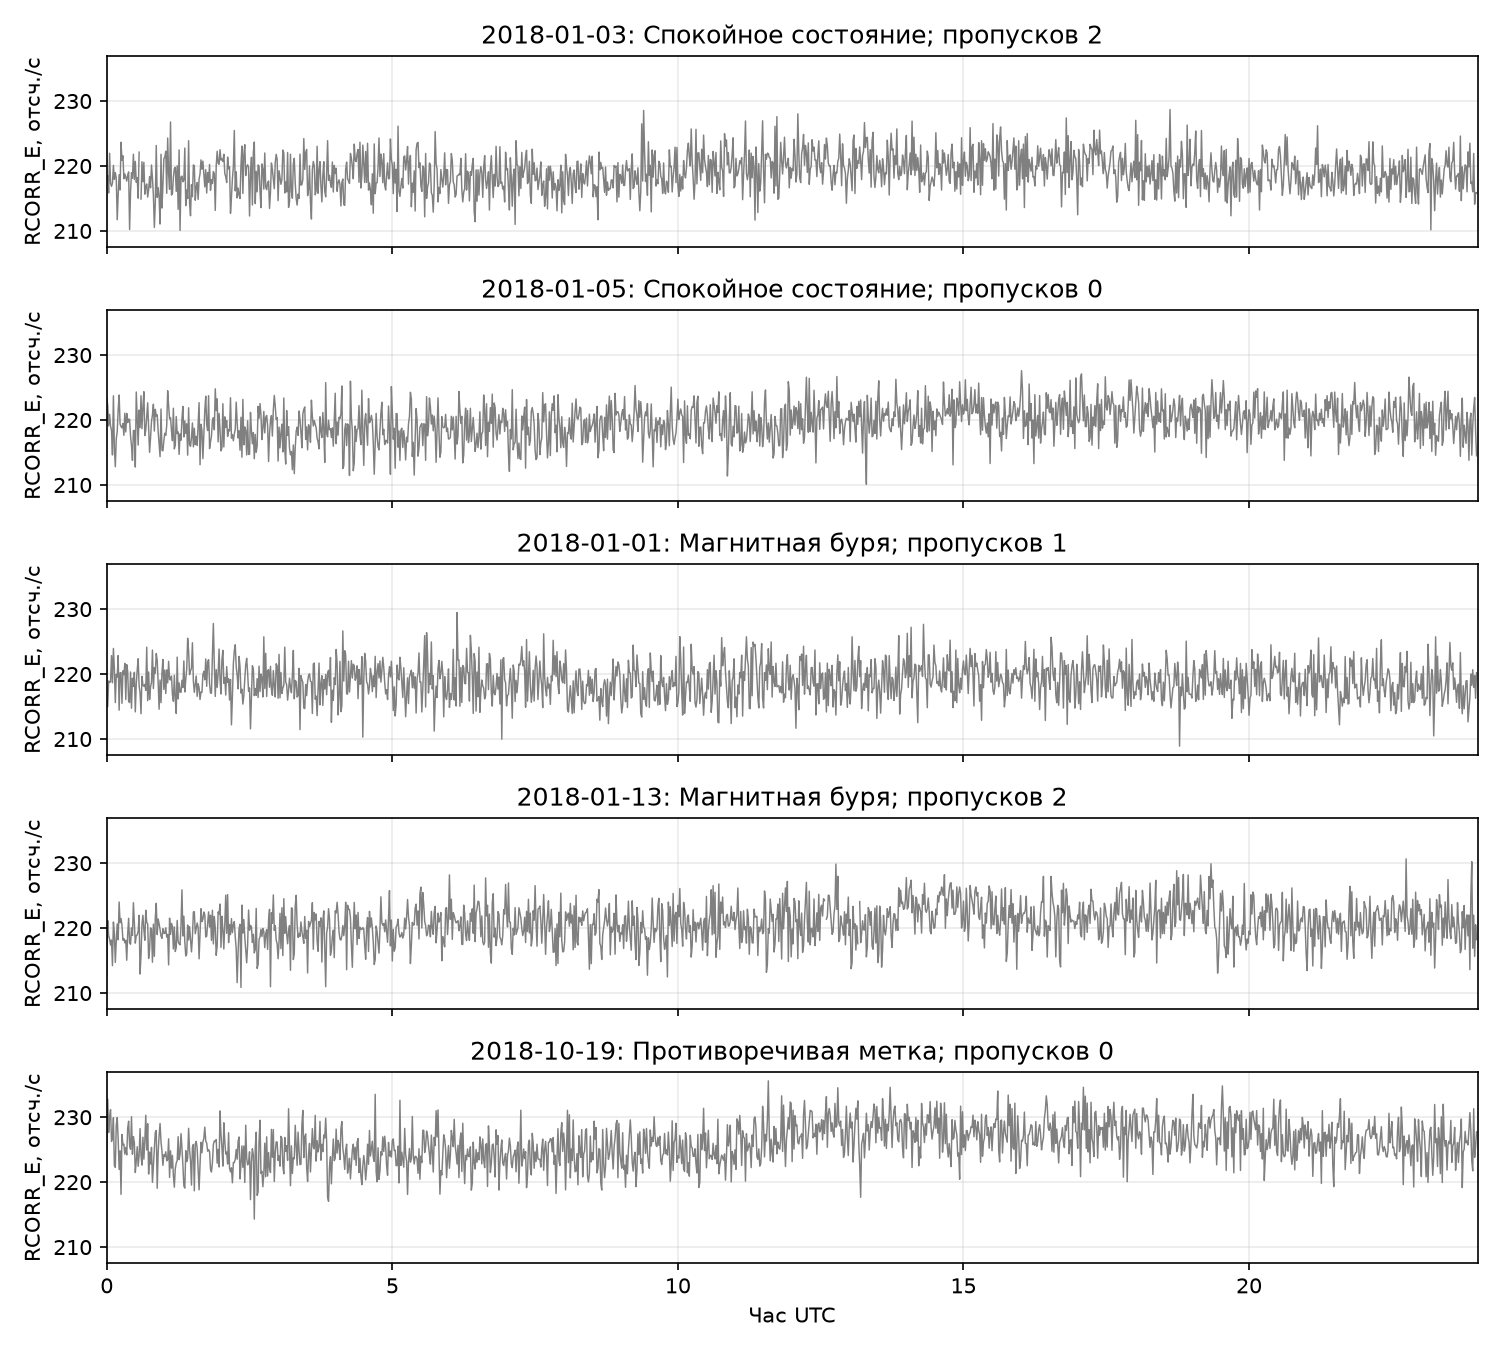

In [4]:
example_dates = ['2018-01-03', '2018-01-05', '2018-01-01',
                 '2018-01-13', '2018-10-19']
example_labels = ['Спокойное состояние', 'Спокойное состояние',
                  'Магнитная буря', 'Магнитная буря', 'Противоречивая метка']
fig_raw, axes = plt.subplots(5, 1, figsize=(10, 9), sharex=True, sharey=True)
for ax, date, label in zip(axes, example_dates, example_labels):
    ax.plot(np.arange(1440) / 60, raw[date], color='gray', linewidth=.7)
    ax.set(title=f'{date}: {label}; пропусков {raw[date].isna().sum()}',
           ylabel='RCORR_E, отсч./с', xlim=(0, 24))
    ax.grid(alpha=.25)
axes[-1].set_xlabel('Час UTC')
fig_raw.tight_layout()
plt.show()



## Заполнение пропусков и признаки суток

Пропуски заполняются медианой своих суток, включая фоновые дни. Если сутки
полностью пусты, их медиана не определена; объект без полного фона исключается
с сообщением. Стандартизация применяется по столбцам трёх признаков.

| Признак | Формула | Что описывает |
|---|---|---|
| `amp` | Q90 − Q10 | Разброс основной части значений без крайних 10% с каждой стороны |
| `trend` | median(12:00–23:59) − median(00:00–11:59) | Изменение уровня между половинами дня |
| `shift` | median(сегодня) − median(предыдущих 7 полных суток) | Отклонение от предшествующего недельного уровня |

Это статистические характеристики. `amp` не измеряет силу бури напрямую,
знак `trend` сам не доказывает фазу события.
Длительное событие может попасть в недельный фон и уменьшить `shift`.


In [5]:
# Пропуски во всех рядах, включая фон, заполняем медианой своих суток.
filled, quality_rows = {}, []
for date, series in all_raw.items():
    missing = int(series.isna().sum())
    included = series.notna().any()
    quality_rows.append([date, missing, missing / 1440, bool(included)])
    if included:
        filled[date] = series.fillna(series.median())
    else:
        print(date, 'пустые сутки: исключены из расчёта признаков и фона')
all_quality = pd.DataFrame(quality_rows, columns=[
    'date', 'missing', 'imputed_fraction', 'included']).set_index('date')
quality = all_quality.loc[days.index].copy()
rows = []
for date in days.index:
    week = week_dates[date]
    if date not in filled or any(day not in filled for day in week):
        quality.loc[date, 'included'] = False
        print(date, 'исключено: нет измерений за день или часть фоновой недели')
        continue
    values = filled[date].to_numpy()
    background = np.concatenate([filled[day].to_numpy() for day in week])
    amp = np.quantile(values, .9) - np.quantile(values, .1)
    trend = np.median(values[720:]) - np.median(values[:720])
    shift = np.median(values) - np.median(background)
    rows.append([date, amp, trend, shift])
data = pd.DataFrame(rows, columns=['date', *FEATURES]).set_index('date')
mean = data.mean().to_numpy()
scale = data.std(ddof=0).to_numpy()
scale[scale == 0] = 1
x = (data.to_numpy() - mean) / scale
assert np.isfinite(x).all()
print('Матрица признаков:', x.shape)
print('Пропуски в 88 заданных сутках:', quality.missing.sum())
print('Пропуски во всех сутках с фоном:', all_quality.missing.sum())
print('Доля пропусков с фоном:', all_quality.missing.sum() / (1440 * len(all_dates)))
print(quality.sort_values('missing', ascending=False).head())
print('Признаки первых суток:\n', data.head().round(6))



Матрица признаков: (88, 3)
Пропуски в 88 заданных сутках: 229
Пропуски во всех сутках с фоном: 1491
Доля пропусков с фоном: 0.0027105148342059337
            missing  imputed_fraction  included
date                                           
2018-04-12       32          0.022222      True
2019-08-05       32          0.022222      True
2018-06-16       30          0.020833      True
2018-06-18       25          0.017361      True
2021-03-01       11          0.007639      True
Признаки первых суток:
               amp  trend  shift
date                           
2018-01-01  7.233  0.075 -0.980
2018-01-03  7.215  0.970 -0.305
2018-01-05  7.445  1.835  0.690
2018-01-06  6.511  1.300  1.445
2018-01-07  6.571  0.075  2.235


## Пример заполнения пропусков

Выбирается день с наибольшим количеством пропусков. Верхний график показывает исходный ряд, нижний - заполненный, красные точки отмечают добавленные значения.

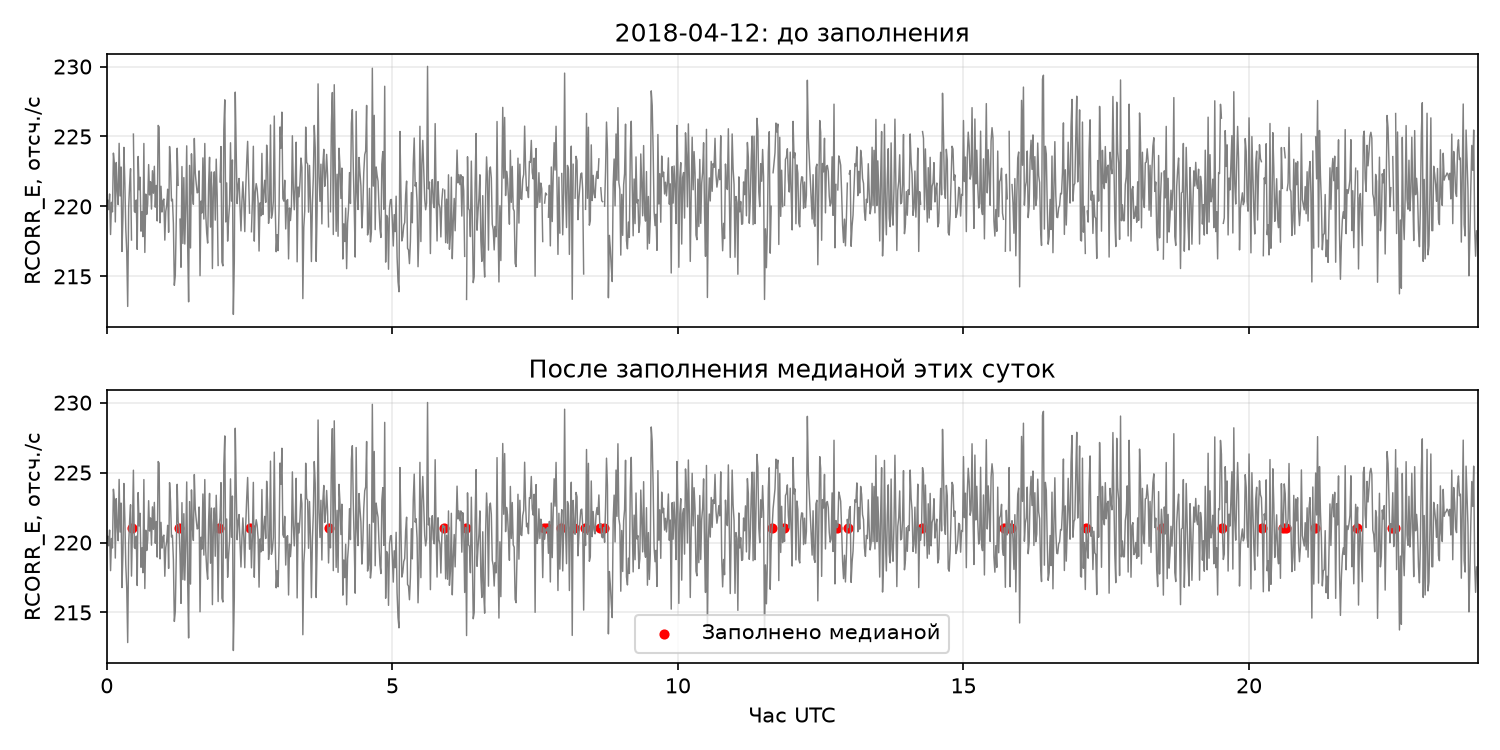

In [6]:
date = quality[quality.included].missing.idxmax()
fig_filled, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True, sharey=True)
hours = np.arange(1440) / 60
axes[0].plot(hours, raw[date], color='gray', linewidth=.7)
axes[0].set_title(f'{date}: до заполнения')
axes[1].plot(hours, filled[date], color='gray', linewidth=.7)
mask = raw[date].isna()
axes[1].scatter(hours[mask], filled[date][mask], color='red', s=15,
                label='Заполнено медианой')
axes[1].set_title('После заполнения медианой этих суток')
axes[1].legend()
for ax in axes:
    ax.set(ylabel='RCORR_E, отсч./с', xlim=(0, 24))
    ax.grid(alpha=.25)
axes[1].set_xlabel('Час UTC')
fig_filled.tight_layout()
plt.show()



## Метод нечётких c средних

FCM чередует взвешенное вычисление центров и пересчёт принадлежностей. U имеет размер "кластеры * наблюдения", сумма каждого столбца равна единице. При точном совпадении с центром деление на ноль обрабатывается отдельно. FPC выше - принадлежности чётче; Xie–Beni ниже - лучше компактность относительно расстояния между центрами; силуэт выше - лучше жёсткое разбиение по argmax U.

In [7]:
def memberships(data, centers, m=2):
    d2 = np.sum((centers[:, None] - data[None, :])**2, axis=2)
    u = np.zeros_like(d2)
    exact = (d2 == 0).any(axis=0)
    if exact.any():
        zero = d2[:, exact] == 0
        u[:, exact] = zero / zero.sum(axis=0)
    weights = np.maximum(d2[:, ~exact], np.finfo(float).tiny)**(-1 / (m - 1))
    u[:, ~exact] = weights / weights.sum(axis=0)
    return u, d2

def fcm(data, c=2, m=2, seed=42, n_init=10, tol=1e-6, max_iter=1000):
    assert 1 < c < len(data) and m > 1
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_init):
        u = rng.random((c, len(data)))
        u /= u.sum(axis=0)
        history = []
        for _ in range(max_iter):
            weights = u**m
            centers = weights @ data / weights.sum(axis=1, keepdims=True)
            new_u, d2 = memberships(data, centers, m)
            history.append(float(np.sum(new_u**m * d2)))
            delta = np.max(np.abs(new_u - u))
            u = new_u
            if delta < tol:
                break
        if best is None or history[-1] < best['history'][-1]:
            best = dict(centers=centers, U=u, history=np.array(history),
                        converged=delta < tol)
    return best

def metrics(data, result):
    u, centers = result['U'], result['centers']
    n = len(data)
    fpc = np.sum(u**2) / n
    separation = np.sum((centers[:, None] - centers[None, :])**2, axis=2)
    np.fill_diagonal(separation, np.inf)
    xb = result['history'][-1] / (n * separation.min())
    labels = u.argmax(axis=0)
    distances = np.linalg.norm(data[:, None] - data[None, :], axis=2)
    silhouette = np.zeros(n)
    if 1 < len(np.unique(labels)) < n:
        for i in range(n):
            own = labels == labels[i]
            own[i] = False
            if own.any():
                a = distances[i, own].mean()
                b = min(distances[i, labels == k].mean()
                        for k in np.unique(labels) if k != labels[i])
                silhouette[i] = (b - a) / max(a, b) if max(a, b) else 0
    else:
        silhouette[:] = np.nan
    return [float(fpc), float(xb), float(silhouette.mean())]

def adjusted_rand_index(table):
    table = np.asarray(table)
    choose2 = lambda values: np.sum(values * (values - 1) / 2)
    n = table.sum()
    row_pairs, col_pairs = choose2(table.sum(axis=1)), choose2(table.sum(axis=0))
    expected = row_pairs * col_pairs / (n * (n - 1) / 2)
    denominator = (row_pairs + col_pairs) / 2 - expected
    return (choose2(table) - expected) / denominator if denominator else 1.0



## Проверка реализации на контрольных данных



In [8]:
rng = np.random.default_rng(2026)
known_centers = np.array([[-5., -5.], [0., 5.], [5., -5.]])
sample = np.concatenate([rng.normal(v, .25, (50, 2)) for v in known_centers])
test = fcm(sample, c=3)
nearest = np.linalg.norm(test['centers'][:, None] - known_centers, axis=2).argmin(axis=1)
assert np.mean(nearest[test['U'].argmax(axis=0)] == np.repeat(np.arange(3), 50)) == 1
assert np.allclose(test['U'].sum(axis=0), 1)
assert np.all(np.diff(test['history']) <= 1e-8)
assert np.array_equal(test['U'], fcm(sample, c=3)['U'])
exact, _ = memberships(np.array([[0., 0.]]), np.array([[0., 0.], [2., 2.]]))
assert np.array_equal(exact[:, 0], [1., 0.])
constant = np.ones((5, 2))
constant_scale = constant.std(axis=0)
constant_scale[constant_scale == 0] = 1
assert np.all((constant - constant.mean(axis=0)) / constant_scale == 0)
print('Контрольный пример и проверки FCM пройдены')



Контрольный пример и проверки FCM пройдены


## Кластеризация и сравнение числа кластеров

Основной результат: c=2, m=2, seed=42, 10 запусков, допуск 10⁻⁶, максимум 1000 итераций. Из запусков выбирается минимальное J. Дополнительно сравниваются c=2…5. Метки состояний не передаются алгоритму.

In [9]:
candidates = {c: fcm(x, c=c) for c in range(2, 6)}
comparison = pd.DataFrame([
    [c, *metrics(x, value), len(value['history'])]
    for c, value in candidates.items()
], columns=['c', 'FPC', 'Xie_Beni', 'silhouette', 'iterations'])
result = candidates[2]
order = result['centers'][:, 0].argsort()
result['centers'] = result['centers'][order]
result['U'] = result['U'][order]
U = result['U']
labels = U.argmax(axis=0) + 1
centers = pd.DataFrame(result['centers'] * scale + mean, columns=FEATURES,
                       index=pd.Index([1, 2], name='cluster'))
assignments = data.join(days[['reference_class']])
assignments['cluster'] = labels
assignments['u_1'], assignments['u_2'] = U
assert U.shape == (2, len(data)) and np.allclose(U.sum(axis=0), 1)
assert ((U >= 0) & (U <= 1)).all()
assert np.all(np.diff(result['history']) <= 1e-8)
assert all(value['converged'] for value in candidates.values())
print('Сравнение числа кластеров:\n', comparison.round(6).to_string(index=False))
print('Центры в исходных единицах:\n', centers.round(6))
print('Размер U:', U.shape, 'итераций:', len(result['history']))
print('Число суток в кластерах:\n', assignments.cluster.value_counts().sort_index())
print('Принадлежности всех суток:\n',
      assignments[['cluster', 'u_1', 'u_2']].round(4).to_string())



Сравнение числа кластеров:
  c      FPC  Xie_Beni  silhouette  iterations
 2 0.612705  1.035647    0.248036         132
 3 0.510152  0.440558    0.247838          63
 4 0.453066  0.502603    0.259846         133
 5 0.410676  0.481258    0.218454         209
Центры в исходных единицах:
               amp     trend     shift
cluster                              
1        7.410016  0.899987  0.104299
2        7.642404  0.161037 -0.108569
Размер U: (2, 88) итераций: 132
Число суток в кластерах:
 cluster
1    49
2    39
Name: count, dtype: int64
Принадлежности всех суток:
             cluster     u_1     u_2
date                               
2018-01-01        2  0.4667  0.5333
2018-01-03        1  0.8766  0.1234
2018-01-05        1  0.7664  0.2336
2018-01-06        1  0.6445  0.3555
2018-01-07        1  0.5694  0.4306
2018-01-10        1  0.6089  0.3911
2018-01-11        1  0.8714  0.1286
2018-01-13        1  0.6794  0.3206
2018-01-16        1  0.5388  0.4612
2018-01-17        1  0.6052  

## Сопоставление с эталонными метками после кластеризации

Метки спокойных дней и бурь используются только для таблицы соответствия и ARI.
Спорная дата исключается из оценки. Кластерам не присваиваются физические
названия без проверки: при c=2 нельзя получить три отдельных кластера
спада, восстановления и технического шума. Дополнительные c=3…5 сравниваются
по внутренним метрикам; это не подтверждает физическую природу групп.

На столбчатой диаграмме показано число спокойных дней и бурь в каждом кластере. Числа над столбцами берутся из таблицы соответствия. Используются 87 дней с однозначной меткой.


Строки: 1 — спокойное состояние, 2 — буря; столбцы: кластеры
cluster           1   2
reference_class        
1                31  12
2                17  27
Оценено суток: 87 ARI = 0.100767
ARI сравнивает кластеры с метками задания; 1 означает полное совпадение.


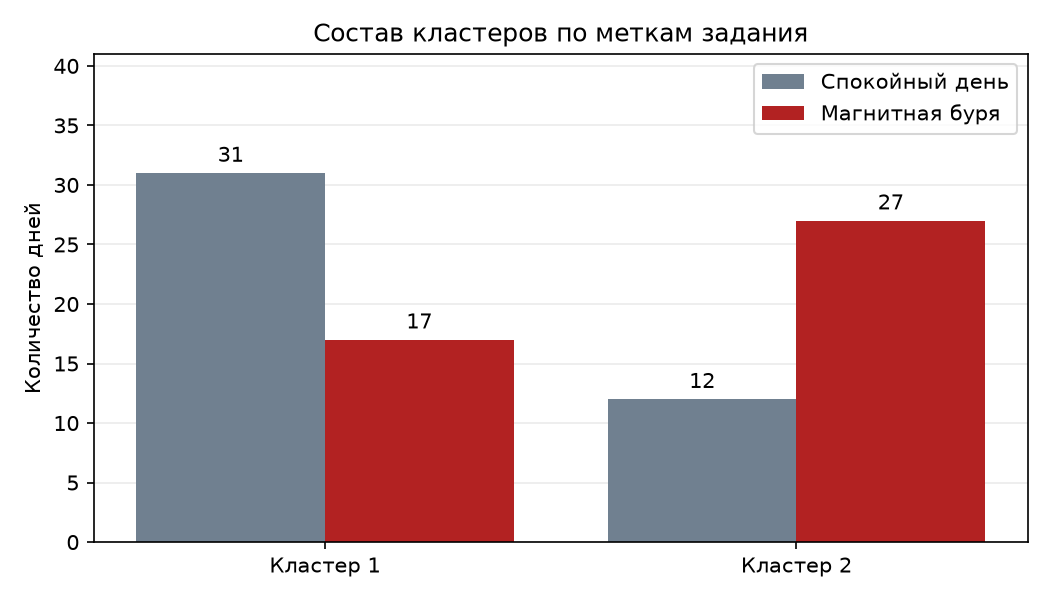

In [10]:
known = assignments.dropna(subset=['reference_class'])
contingency = pd.crosstab(known.reference_class.astype(int), known.cluster)
contingency = contingency.reindex(index=[1, 2], columns=[1, 2], fill_value=0)
ari = adjusted_rand_index(contingency)
print('Строки: 1 — спокойное состояние, 2 — буря; столбцы: кластеры')
print(contingency)
print('Оценено суток:', len(known), 'ARI =', round(ari, 6))
print('ARI сравнивает кластеры с метками задания; 1 означает полное совпадение.')

# Состав кластеров по меткам задания; спорная дата исключена.
fig_contingency, ax = plt.subplots(figsize=(7, 4))
positions = np.arange(2)
for label, name, offset, color in [
    (1, 'Спокойный день', -.2, 'slategray'),
    (2, 'Магнитная буря', .2, 'firebrick'),
]:
    bars = ax.bar(positions + offset, contingency.loc[label].to_numpy(),
                  width=.4, label=name, color=color)
    ax.bar_label(bars, padding=3)
ax.set(xticks=positions, xticklabels=['Кластер 1', 'Кластер 2'],
       ylabel='Количество дней', title='Состав кластеров по меткам задания',
       ylim=(0, contingency.to_numpy().max() + 10))
ax.legend()
ax.grid(axis='y', alpha=.25)
ax.set_axisbelow(True)
fig_contingency.tight_layout()
plt.show()



## Проекция признаков и сходимость

FCM работает по трём стандартизированным признакам. PCA используется
только для двумерного рисунка. Снижение J показывает сходимость оптимизации,
а не физическую правильность кластеров.

Цвет точки показывает кластер FCM: синий — 1, оранжевый — 2. Форма показывает метку из задания: круг — спокойное состояние, треугольник — магнитная буря, X — спорная дата 19.10.2018. Эталонные метки используются здесь только для сопоставления после кластеризации.


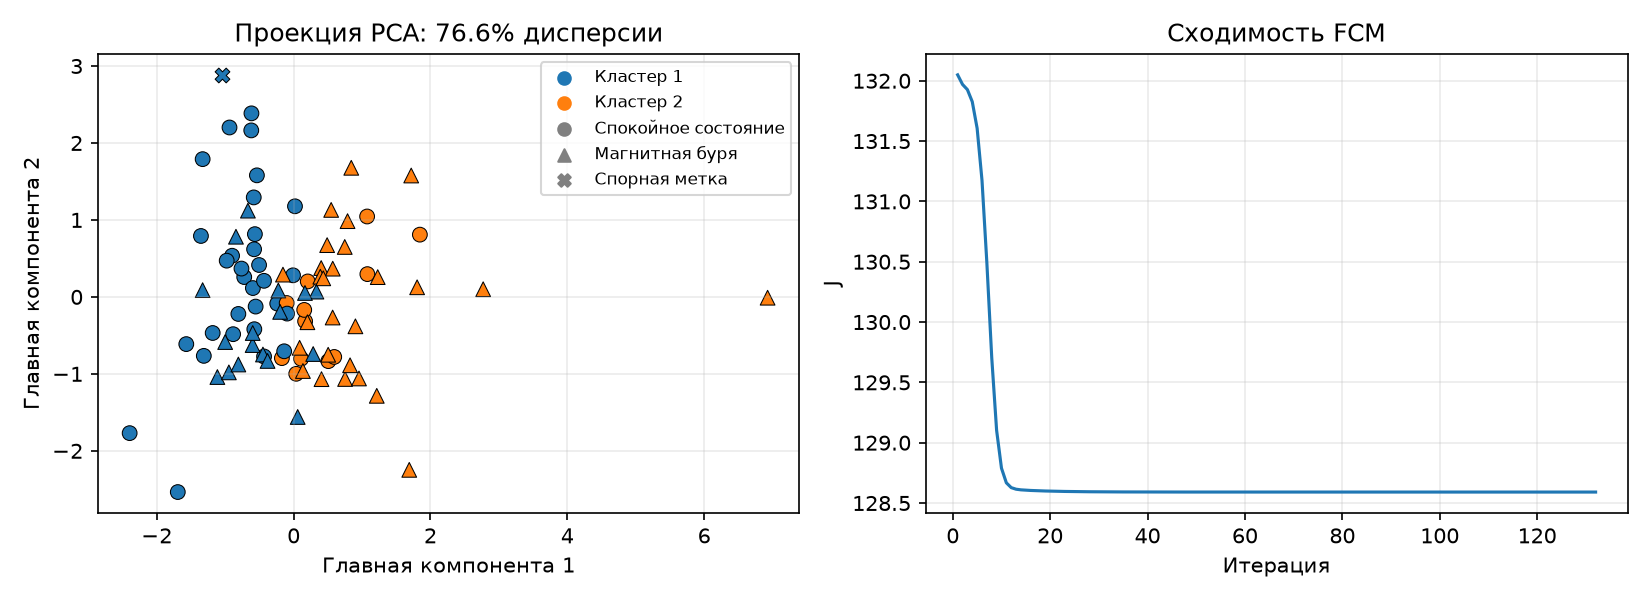

In [11]:
_, singular, vt = np.linalg.svd(x, full_matrices=False)
pca = x @ vt[:2].T
pca_fraction = sum(singular[:2]**2) / sum(singular**2)
fig_result, axes = plt.subplots(1, 2, figsize=(11, 4))
# Цвет — кластер FCM, форма — эталонная метка из задания.
reference = assignments.reference_class.to_numpy()
colors = np.where(labels == 1, 'tab:blue', 'tab:orange')
reference_markers = [(1, 'o', 'Спокойное состояние'),
                     (2, '^', 'Магнитная буря'),
                     (np.nan, 'X', 'Спорная метка')]
for value, marker, name in reference_markers:
    mask = np.isnan(reference) if np.isnan(value) else reference == value
    axes[0].scatter(*pca[mask].T, c=colors[mask], marker=marker,
                    s=50, edgecolors='black', linewidths=.5)
for k, color in [(1, 'tab:blue'), (2, 'tab:orange')]:
    axes[0].scatter([], [], color=color, label=f'Кластер {k}')
for _, marker, name in reference_markers:
    axes[0].scatter([], [], color='gray', marker=marker, label=name)
axes[0].set(xlabel='Главная компонента 1', ylabel='Главная компонента 2',
            title=f'Проекция PCA: {pca_fraction:.1%} дисперсии')
axes[0].legend(loc='upper right', fontsize=8)
axes[1].plot(np.arange(1, len(result['history']) + 1), result['history'])
axes[1].set(xlabel='Итерация', ylabel='J', title='Сходимость FCM')
for ax in axes:
    ax.grid(alpha=.25)
fig_result.tight_layout()
plt.show()



## Степени принадлежности суток

Каждый столбец — отдельные сутки, строки — два кластера. Порядок дат не означает равные реальные интервалы между ними.

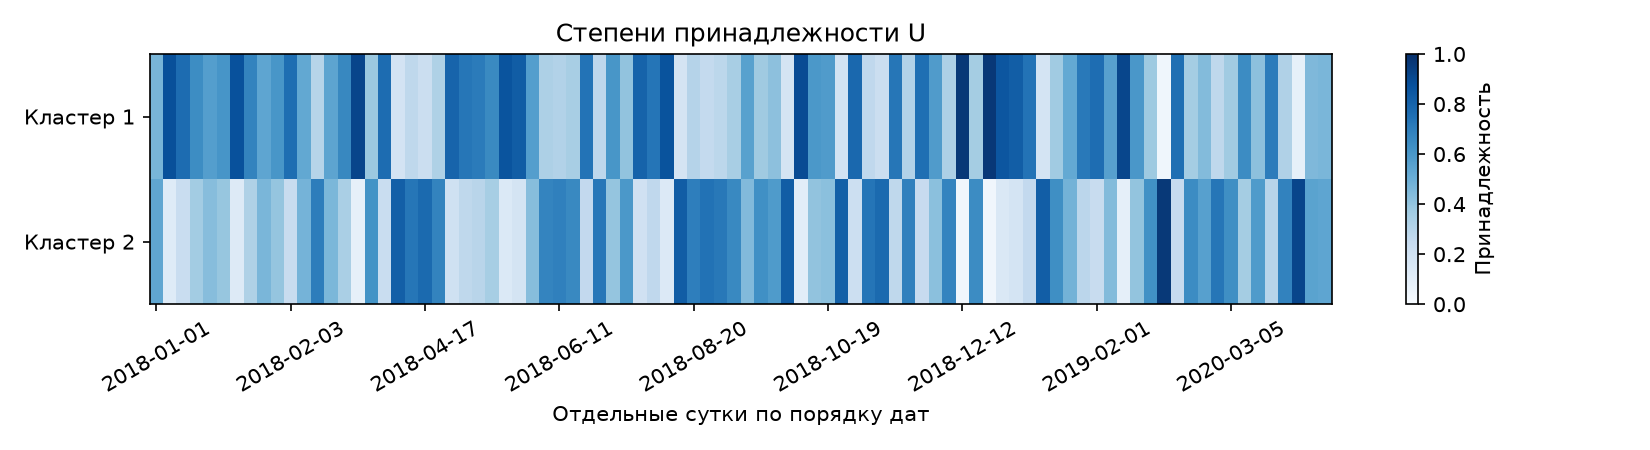

In [12]:
fig_memberships, ax = plt.subplots(figsize=(11, 3))
image = ax.imshow(U, aspect='auto', vmin=0, vmax=1, cmap='Blues')
ticks = np.arange(0, len(data), 10)
ax.set(yticks=[0, 1], yticklabels=['Кластер 1', 'Кластер 2'], xticks=ticks,
       xticklabels=data.index[ticks], title='Степени принадлежности U',
       xlabel='Отдельные сутки по порядку дат')
ax.tick_params(axis='x', rotation=30)
fig_memberships.colorbar(image, ax=ax, label='Принадлежность')
fig_memberships.tight_layout()
plt.show()



## Выводы

Оценка основана на фактически полученных центрах, принадлежностях и ARI.
Недельный фон учитывает предшествующий уровень, но может включать саму бурю.
Отрицательный или положительный trend показывает направление изменения уровня,
не устанавливая причину.
Для проверки фаз событий и технических сбоев нужна отдельная разметка.


In [13]:
print('Обработано', len(data), 'суток, фон — предыдущие 7 суток каждого дня.')
print('Признаки amp, trend и shift стандартизированы; FCM сошёлся.')
print(f'ARI = {ari:.5f}; физические имена кластерам автоматически не присваиваются.')
print('Отрицательный trend — снижение уровня внутри дня; положительный — рост.')
print('Отрицательный shift — уровень ниже недельной медианы, положительный — выше.')
best_c = int(comparison.loc[comparison.Xie_Beni.idxmin(), 'c'])
print('По Xie–Beni среди c=2…5 лучше c=', best_c)



Обработано 88 суток, фон — предыдущие 7 суток каждого дня.
Признаки amp, trend и shift стандартизированы; FCM сошёлся.
ARI = 0.10077; физические имена кластерам автоматически не присваиваются.
Отрицательный trend — снижение уровня внутри дня; положительный — рост.
Отрицательный shift — уровень ниже недельной медианы, положительный — выше.
По Xie–Beni среди c=2…5 лучше c= 3
